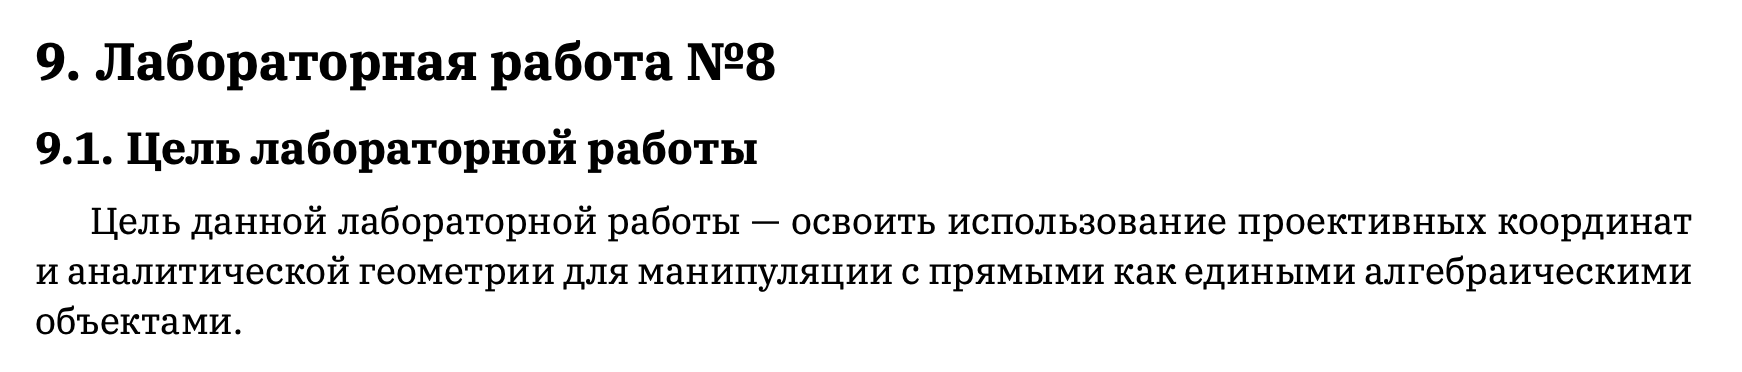

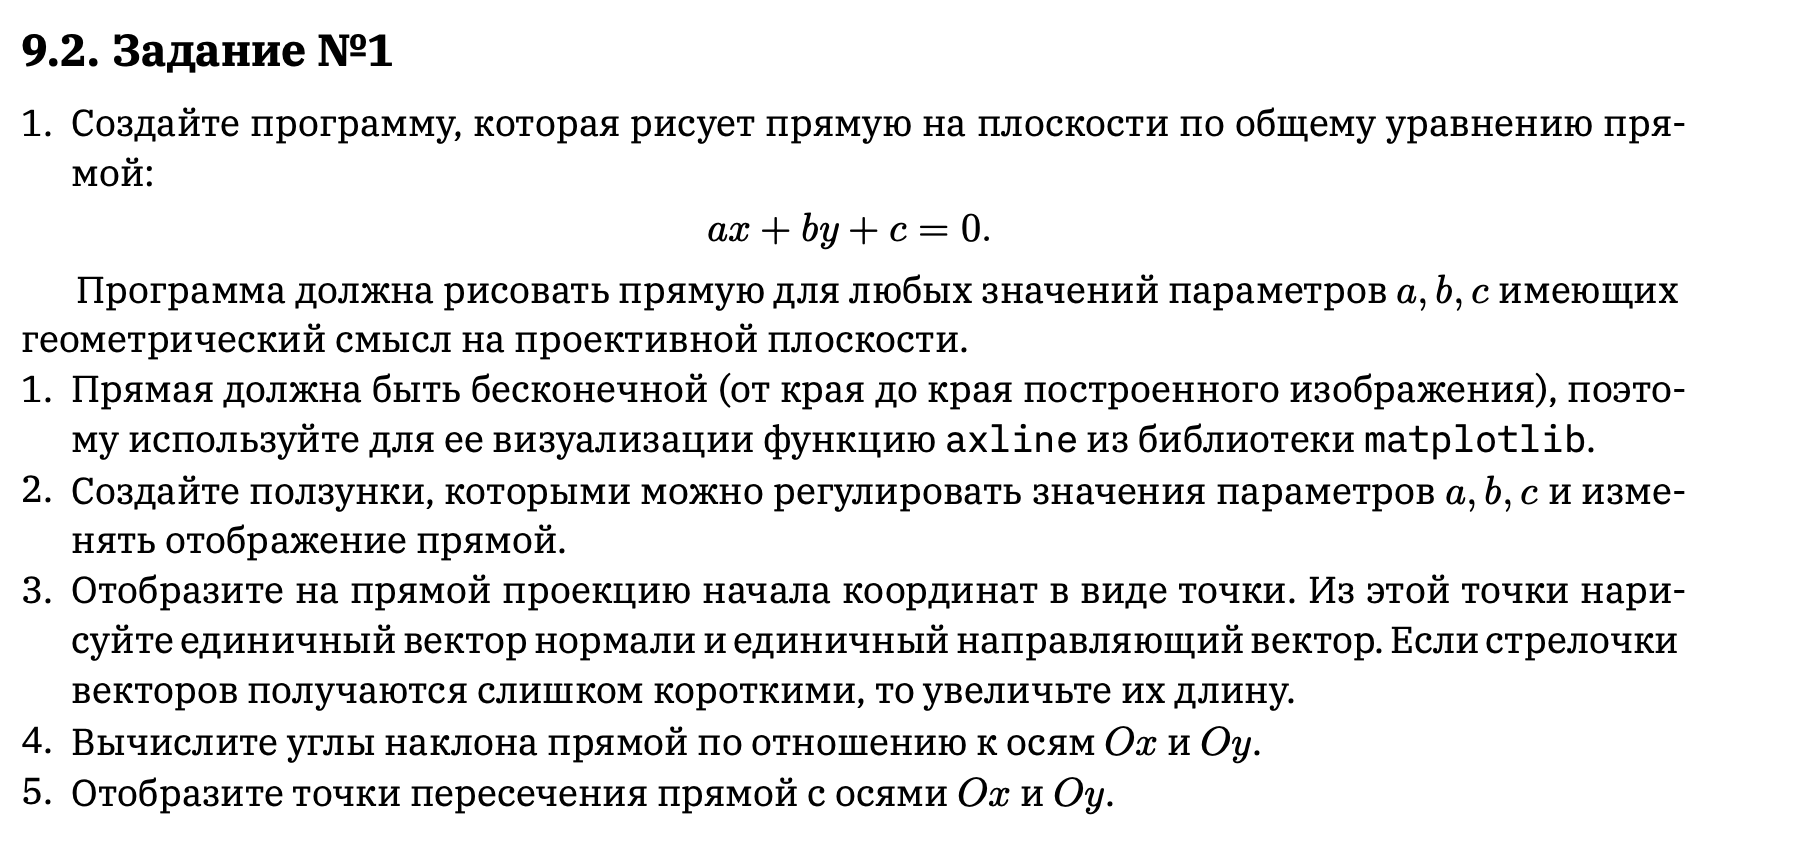

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

In [6]:
def plot_general_line(a=1.0, b=1.0, c=0.0):
    xlim = (-5, 5)
    ylim = (-5, 5)
    fig, ax = plt.subplots(figsize=(7,7))
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(rf"Прямая: ${a:.2f}x + {b:.2f}y + {c:.2f} = 0$")

    # 1. Рисуем прямую с помощью axline
    if b != 0:
        y0 = -(a*0 + c)/b
        point_on_line = np.array([0, y0])
        direction = np.array([1, -a/b])
    elif a != 0:
        x0 = -(b*0 + c)/a
        point_on_line = np.array([x0, 0])
        direction = np.array([-b/a, 1])
    else:
        ax.text(0, 0, "Нет прямой (a=b=0)", color='red', fontsize=16)
        plt.show()
        return

    if direction[0] != 0:
        slope = direction[1]/direction[0]
        ax.axline(point_on_line, slope=slope, color='blue', linewidth=2, label='Прямая')
    else:
        ax.axvline(point_on_line[0], color='blue', linewidth=2, label='Прямая')

    # 2. Проекция начала координат на прямую
    P = np.array([0.0, 0.0])
    denom = a**2 + b**2
    if denom != 0:
        t = (a*P[0] + b*P[1] + c) / denom
        proj = P - t * np.array([a, b])
        ax.plot(proj[0], proj[1], 'ro', label='Проекция O')
        # 3. Нормаль (единичная)
        normal = np.array([a, b])
        normal = normal / np.linalg.norm(normal)
        ax.arrow(proj[0], proj[1], normal[0], normal[1], head_width=0.2, head_length=0.2, fc='r', ec='r', label='Нормаль')
        # 4. Направляющий вектор (единичный, ортогонален нормали)
        direction_unit = np.array([-b, a])
        direction_unit = direction_unit / np.linalg.norm(direction_unit)
        ax.arrow(proj[0], proj[1], direction_unit[0], direction_unit[1], head_width=0.2, head_length=0.2, fc='g', ec='g', label='Направляющий')
    else:
        proj = np.array([np.nan, np.nan])

    # 5. Углы наклона
    if b != 0:
        angle_x = np.degrees(np.arctan(-a/b))
    else:
        angle_x = 90.0 if a != 0 else np.nan
    if a != 0:
        angle_y = np.degrees(np.arctan(-b/a))
    else:
        angle_y = 90.0 if b != 0 else np.nan
    ax.text(0.05, 0.95, f"Угол с Ox: {angle_x:.1f}°\nУгол с Oy: {angle_y:.1f}°", transform=ax.transAxes, fontsize=12, verticalalignment='top')

    # 6. Точки пересечения с осями
    if b != 0:
        y_cross = -(a*0 + c)/b
        ax.plot(0, y_cross, 'mo', label='Пересечение с Oy')
    if a != 0:
        x_cross = -(b*0 + c)/a
        ax.plot(x_cross, 0, 'co', label='Пересечение с Ox')

    ax.legend()
    plt.show()

interact(
    plot_general_line,
    a=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='a'),
    b=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='b'),
    c=FloatSlider(value=0.0, min=-10.0, max=10.0, step=0.1, description='c'),
)

interactive(children=(FloatSlider(value=1.0, description='a', max=5.0, min=-5.0), FloatSlider(value=1.0, descr…

<function __main__.plot_general_line(a=1.0, b=1.0, c=0.0)>

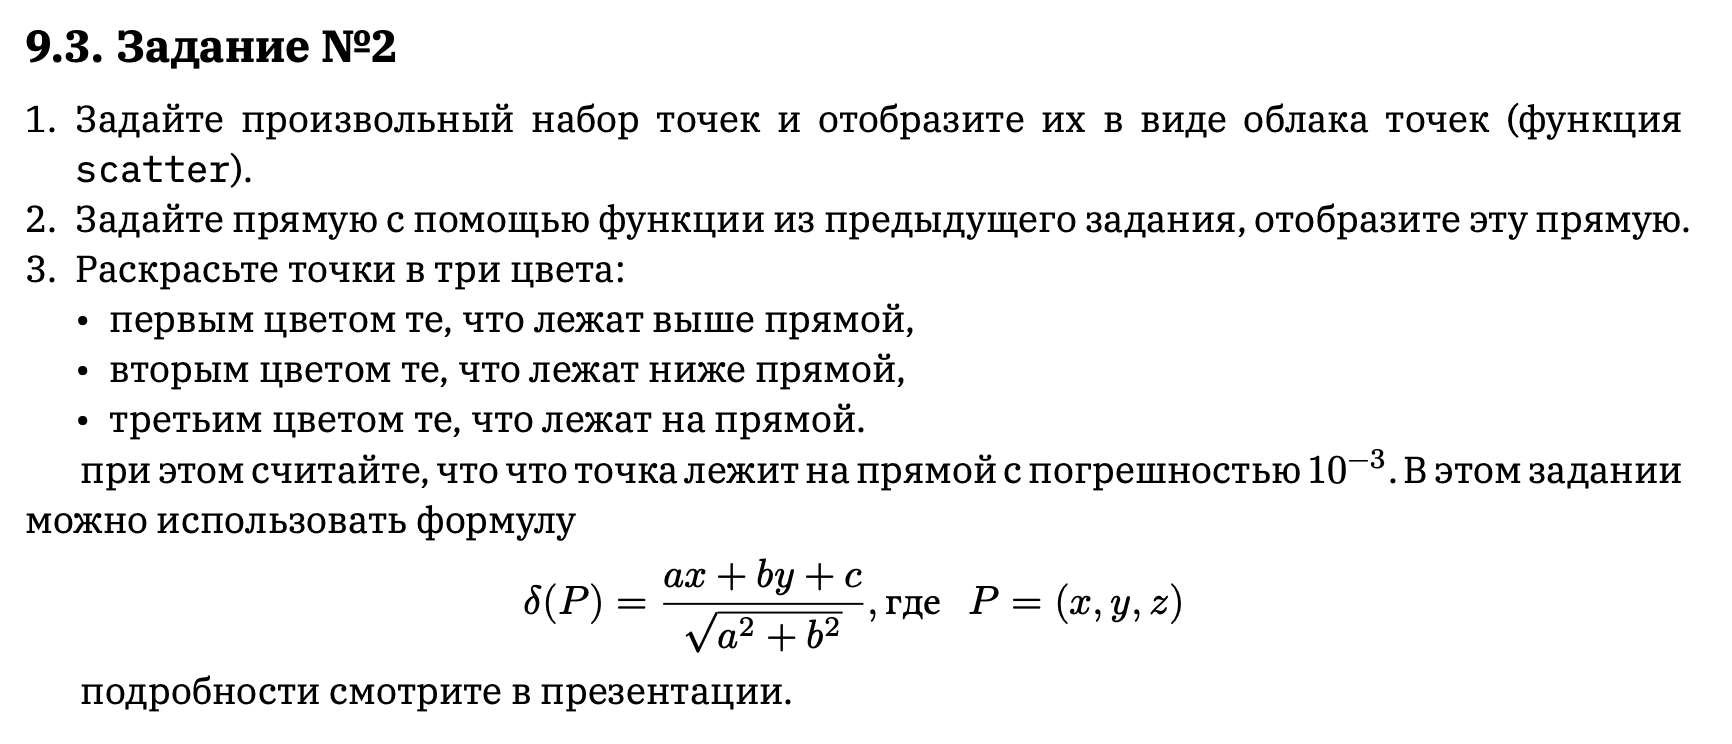

In [9]:
def plot_points_and_line(a=1.0, b=1.0, c=0.0, n_points=30, seed=42):
    np.random.seed(seed)
    # 1. Генерируем облако точек
    X = np.random.uniform(-5, 5, n_points)
    Y = np.random.uniform(-5, 5, n_points)
    points = np.column_stack([X, Y])
    
    # 2. Вычисляем δ(P) для каждой точки
    denom = np.sqrt(a**2 + b**2) if (a**2 + b**2) != 0 else 1
    delta = (a*X + b*Y + c) / denom
    tol = 1e-3
    colors = np.where(np.abs(delta) < tol, 'orange', np.where(delta > 0, 'blue', 'red'))
    
    # 3. Рисуем точки
    fig, ax = plt.subplots(figsize=(7,7))
    ax.scatter(X, Y, c=colors, s=80, edgecolor='black', label='Точки')
    
    # 4. Рисуем прямую (как в предыдущем задании)
    if b != 0:
        y0 = -(a*0 + c)/b
        point_on_line = np.array([0, y0])
        direction = np.array([1, -a/b])
    elif a != 0:
        x0 = -(b*0 + c)/a
        point_on_line = np.array([x0, 0])
        direction = np.array([-b/a, 1])
    else:
        ax.text(0, 0, "Нет прямой (a=b=0)", color='red', fontsize=16)
        plt.show()
        return
    if direction[0] != 0:
        slope = direction[1]/direction[0]
        ax.axline(point_on_line, slope=slope, color='green', linewidth=2, label='Прямая')
    else:
        ax.axvline(point_on_line[0], color='green', linewidth=2, label='Прямая')

    # 5. Легенда и оформление
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='На прямой', markerfacecolor='orange', markeredgecolor='k', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Выше прямой', markerfacecolor='blue', markeredgecolor='k', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Ниже прямой', markerfacecolor='red', markeredgecolor='k', markersize=10),
        Line2D([0], [0], color='green', lw=2, label='Прямая')
    ]
    ax.legend(handles=legend_elements)
    ax.set_aspect('equal')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(rf"Точки и прямая: ${a:.2f}x + {b:.2f}y + {c:.2f} = 0$")
    ax.grid(True)
    plt.show()

interact(
    plot_points_and_line,
    a=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='a'),
    b=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='b'),
    c=FloatSlider(value=0.0, min=-10.0, max=10.0, step=0.1, description='c'),
    n_points=IntSlider(value=30, min=5, max=100, step=1, description='Кол-во точек'),
    seed=IntSlider(value=42, min=0, max=1000, step=1, description='Seed')
)

interactive(children=(FloatSlider(value=1.0, description='a', max=5.0, min=-5.0), FloatSlider(value=1.0, descr…

<function __main__.plot_points_and_line(a=1.0, b=1.0, c=0.0, n_points=30, seed=42)>

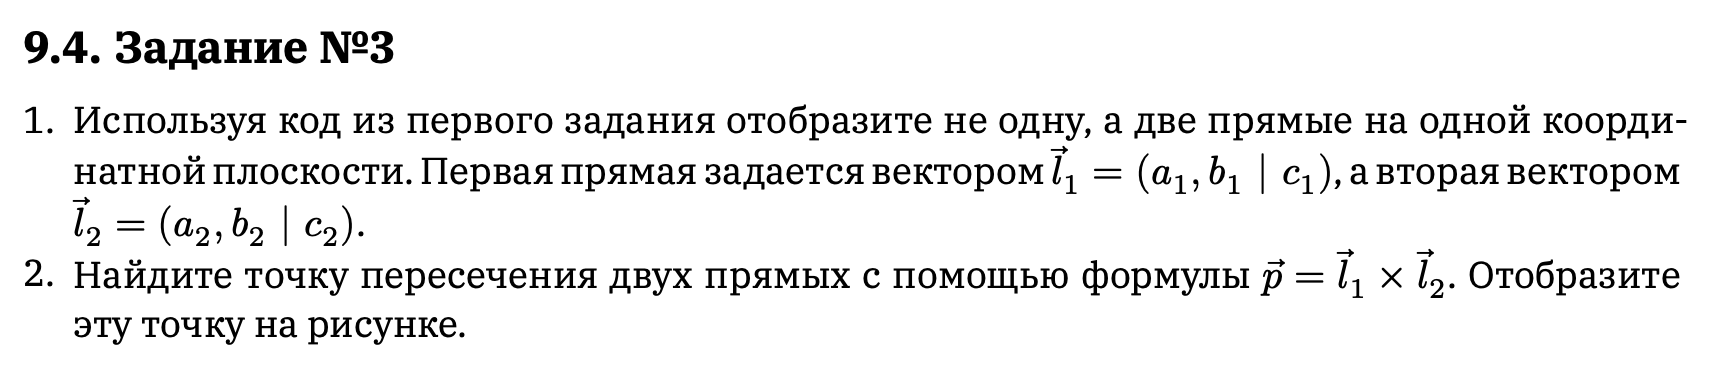

In [10]:
def plot_two_lines_and_intersection(a1=1.0, b1=1.0, c1=0.0, a2=-1.0, b2=1.0, c2=0.0):
    xlim = (-5, 5)
    ylim = (-5, 5)
    fig, ax = plt.subplots(figsize=(7,7))
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title("Две прямые и их точка пересечения")

    # Первая прямая
    if b1 != 0:
        y0_1 = -(a1*0 + c1)/b1
        point1 = np.array([0, y0_1])
        direction1 = np.array([1, -a1/b1])
    elif a1 != 0:
        x0_1 = -(b1*0 + c1)/a1
        point1 = np.array([x0_1, 0])
        direction1 = np.array([-b1/a1, 1])
    else:
        ax.text(0, 0, "Нет первой прямой (a1=b1=0)", color='red', fontsize=16)
        plt.show()
        return

    if direction1[0] != 0:
        slope1 = direction1[1]/direction1[0]
        ax.axline(point1, slope=slope1, color='blue', linewidth=2, label='Прямая 1')
    else:
        ax.axvline(point1[0], color='blue', linewidth=2, label='Прямая 1')

    # Вторая прямая
    if b2 != 0:
        y0_2 = -(a2*0 + c2)/b2
        point2 = np.array([0, y0_2])
        direction2 = np.array([1, -a2/b2])
    elif a2 != 0:
        x0_2 = -(b2*0 + c2)/a2
        point2 = np.array([x0_2, 0])
        direction2 = np.array([-b2/a2, 1])
    else:
        ax.text(0, 0, "Нет второй прямой (a2=b2=0)", color='red', fontsize=16)
        plt.show()
        return

    if direction2[0] != 0:
        slope2 = direction2[1]/direction2[0]
        ax.axline(point2, slope=slope2, color='green', linewidth=2, label='Прямая 2')
    else:
        ax.axvline(point2[0], color='green', linewidth=2, label='Прямая 2')

    # Точка пересечения через векторное произведение
    l1 = np.array([a1, b1, c1])
    l2 = np.array([a2, b2, c2])
    p = np.cross(l1, l2)
    if np.abs(p[2]) > 1e-8:
        x_int = p[0]/p[2]
        y_int = p[1]/p[2]
        ax.plot(x_int, y_int, 'ro', markersize=10, label='Точка пересечения')
        ax.text(x_int, y_int, f'  ({x_int:.2f}, {y_int:.2f})', color='red', fontsize=12)
    else:
        ax.text(0, 0, "Прямые параллельны или совпадают", color='orange', fontsize=14)

    ax.legend()
    plt.show()

interact(
    plot_two_lines_and_intersection,
    a1=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='a1'),
    b1=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='b1'),
    c1=FloatSlider(value=0.0, min=-10.0, max=10.0, step=0.1, description='c1'),
    a2=FloatSlider(value=-1.0, min=-5.0, max=5.0, step=0.1, description='a2'),
    b2=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='b2'),
    c2=FloatSlider(value=0.0, min=-10.0, max=10.0, step=0.1, description='c2'),
)

interactive(children=(FloatSlider(value=1.0, description='a1', max=5.0, min=-5.0), FloatSlider(value=1.0, desc…

<function __main__.plot_two_lines_and_intersection(a1=1.0, b1=1.0, c1=0.0, a2=-1.0, b2=1.0, c2=0.0)>

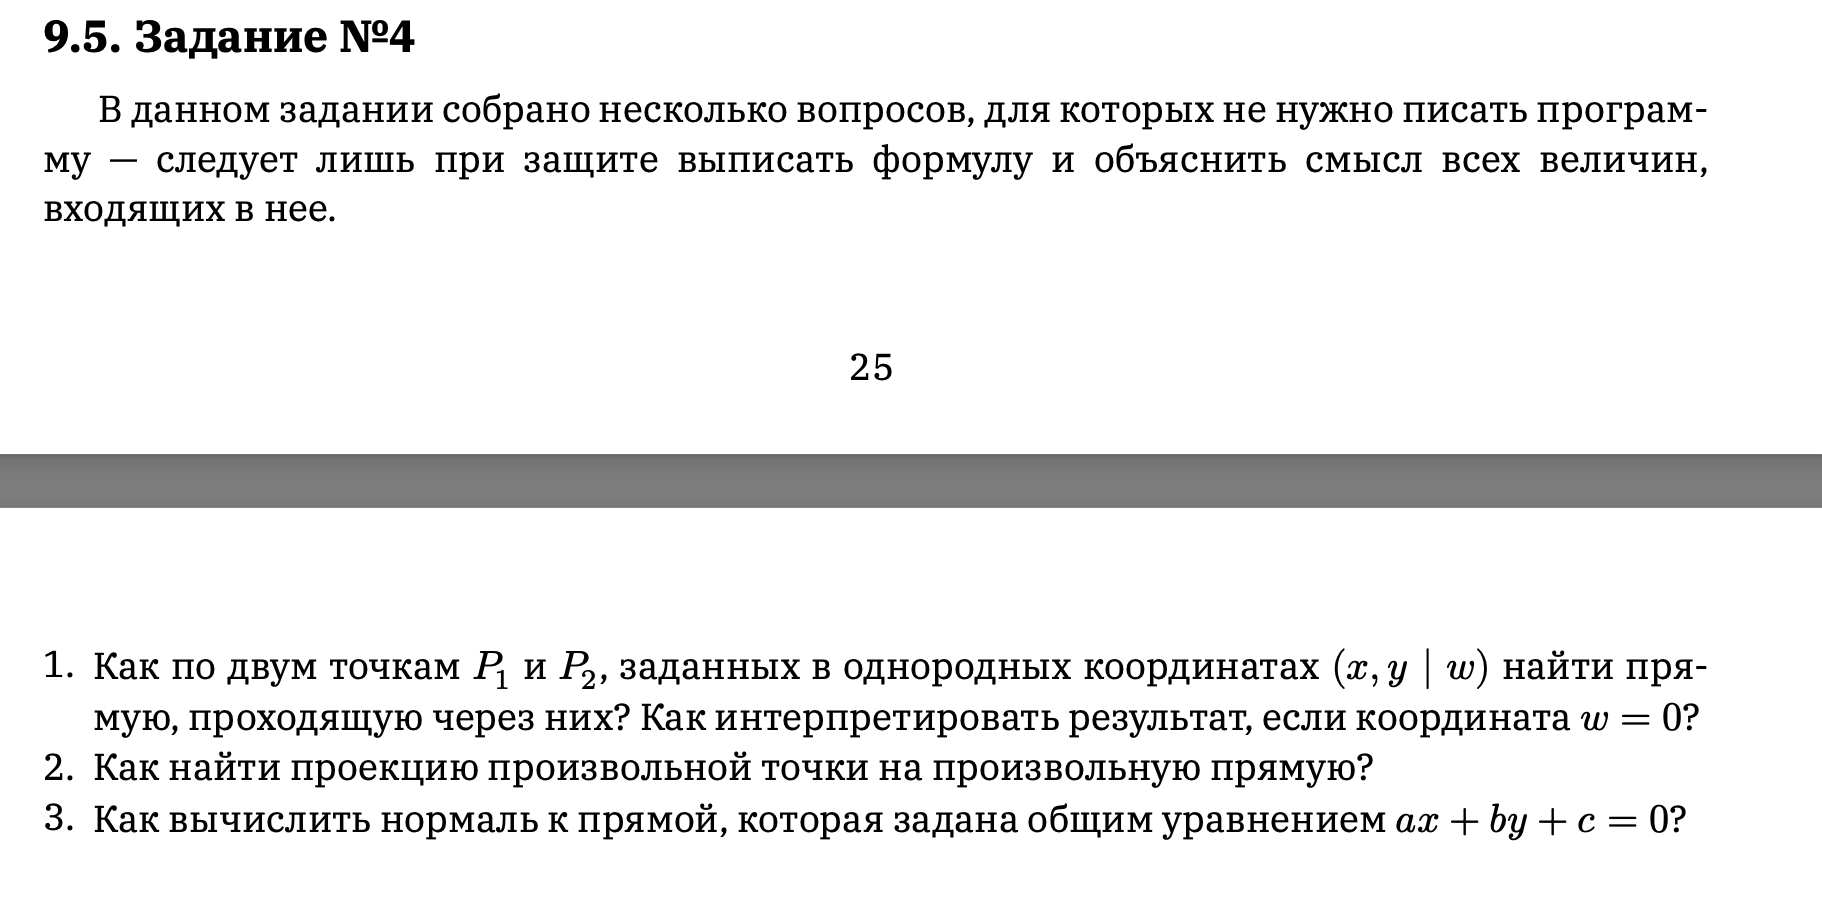

### 9.5. Задание №4 — Формулы и пояснения

1. **Как по двум точкам 𝑃₁ и 𝑃₂, заданных в однородных координатах (𝑥, 𝑦 | 𝑤), найти прямую, проходящую через них? Как интерпретировать результат, если координата 𝑤 = 0?**

Формула:

```Tex
l = P₁ × P₂
```

где `×` — векторное произведение,  
`P₁ = (x₁, y₁, w₁)`, `P₂ = (x₂, y₂, w₂)` — однородные координаты точек.

**Смысл величин:**  
- `x, y, w` — однородные координаты точки на проективной плоскости.  
- Если `w = 0`, точка находится на бесконечности (это направление, а не обычная точка).

---

2. **Как найти проекцию произвольной точки на произвольную прямую?**

Формула:

```Tex
P_proj = P - ((a x + b y + c) / (a² + b²)) * (a, b, 0)
```

где  
- `P = (x, y, 1)` — координаты точки,  
- `l = (a, b, c)` — коэффициенты общего уравнения прямой.

**Смысл величин:**  
- `(a, b, c)` — коэффициенты прямой.  
- `(x, y)` — координаты точки.  
- `P_proj` — ортогональная проекция точки на прямую.

---

3. **Как вычислить нормаль к прямой, которая задана общим уравнением 𝑎𝑥 + 𝑏𝑦 + 𝑐 = 0?**

Формула:

```Tex
n = (a, b) n₀ = (a, b) / sqrt(a² + b²)
```

где  
- `n` — вектор нормали,  
- `n₀` — единичный вектор нормали.

**Смысл величин:**  
- `(a, b)` — координаты нормального вектора к прямой.  
- Нормаль всегда перпендикулярна прямой `a x + b y + c = 0`.